## 1.
Importamos las librerias

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2.
Cargamos los datos con la función read_csv de pandas y visualizamos las primeras filas.
Después, mostramos los tipos de todas las columnas.

In [2]:
datos = pd.read_csv("data.csv")
display(datos.head(5))
print(datos.dtypes.to_string())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
Street            object
Alley             object
LotShape          object
LandContour       object
Utilities         object
LotConfig         object
LandSlope         object
Neighborhood      object
Condition1        object
Condition2        object
BldgType          object
HouseStyle        object
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle         object
RoofMatl          object
Exterior1st       object
Exterior2nd       object
MasVnrType        object
MasVnrArea       float64
ExterQual         object
ExterCond         object
Foundation        object
BsmtQual          object
BsmtCond          object
BsmtExposure      object
BsmtFinType1      object
BsmtFinSF1         int64
BsmtFinType2      object
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
Heating           object


## 3.
En este apartado vamos a calcular el número total de viviendas y a identificar qué columnas contienen datos nulos.

In [3]:
viviendas = len(datos)
print(f"Hay un total de {viviendas} viviendas.\n")
nulos = datos.isnull().sum(axis=0)
v_nulas = nulos[nulos > 0]
print(v_nulas.to_string())

Hay un total de 1460 viviendas.

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406


## 4.
Estudio individual de varias variables
Primero mostraremos los datos y despues haremos su analisis:

In [4]:
def estudio(datos, variable):
    print(f"VARIABLE: {variable}")
    print(f"Tipo de dato: {datos[variable].dtype}")
    
    nulos = datos[variable].isnull().sum()
    print(f"Valores nulos: {nulos}")
    
    if datos[variable].dtype in ['int64', 'float64']:
        print(f"Mínimo: {datos[variable].min()}")
        print(f"Máximo: {datos[variable].max()}")
    else:
        print(f"Valores únicos: {datos[variable].unique().tolist()}")


In [5]:
estudio(datos, 'Id')

VARIABLE: Id
Tipo de dato: int64
Valores nulos: 0
Mínimo: 1
Máximo: 1460


### 4.1 Analisis de la variable : Id
Valores únicos: [1, 2, 3, ..., 1460]. Son exactamente 1460 valores únicos correlativos, coincidiendo con el número total de viviendas del conjunto de datos. Sirven únicamente como identificador de fila.

Tipo de variable: Numérica discreta.

Análisis de nulos y tratamiento: Existen 0 valores nulos, por lo que no es necesario aplicar ninguna estrategia de tratamiento.

Estudio: El rango va desde un mínimo de 1 hasta un máximo de 1460. No existen valores atípicos (outliers) ya que es un identificador secuencial.

Decisión sobre eliminación: Se decide eliminar la columna. Su aportación es irrelevante ya que el identificador de la fila no guarda ninguna relación matemática real con las características de la casa.

Recodificación: No ya que hemos decidido eliminarla.

In [6]:
datos = datos.drop('Id', axis=1)

In [7]:
estudio(datos, 'MSSubClass')

VARIABLE: MSSubClass
Tipo de dato: int64
Valores nulos: 0
Mínimo: 20
Máximo: 190


### 4.2 Analisis de la variable : MSSubClass

Valores únicos: [20, 30,.., 190]. Identifican los distintos tipos.

Tipo de variable: Categórica sin orden (nominal), aunque esté originalmente codificada con números.

Análisis de nulos y tratamiento: Existen 0 valores nulos, por lo que no es necesario aplicar ninguna estrategia de tratamiento.

Estudio: El código detecta un rango desde un mínimo de 20 hasta un máximo de 190. Sin embargo, al tratarse de etiquetas categóricas, los conceptos de mínimo, máximo o valores atípicos (outliers) no son aplicables analíticamente.

Decisión sobre eliminación: No se elimina. Aporta información relevante sobre las características de la vivienda

Recodificación: Sí es necesaria. Para evitar que el algoritmo aplique matemáticas sobre las etiquetas, la recodificamos transformando la columna a tipo texto usando astype(str).

In [8]:
datos['MSSubClass'] = datos['MSSubClass'].astype(str)


In [9]:
estudio(datos, 'MSZoning')

VARIABLE: MSZoning
Tipo de dato: object
Valores nulos: 0
Valores únicos: ['RL', 'RM', 'C (all)', 'FV', 'RH']


### 4.3 Analisis de la variable : MSZoning

Valores únicos: ['RL', 'RM', 'C (all)', 'FV', 'RH']. Identifican la clasificación general de zonificación de la venta.

Tipo de variable: Categórica sin orden (nominal).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar tratamiento.

Estudio: Al ser categórica, la función devuelve sus etiquetas textuales. Describen el tipo de zona donde se ubica la propiedad (residencial de baja densidad, media densidad, comercial, etc.).

Decisión sobre eliminación: No se elimina. La zonificación es una característica determinante en el valor del terreno y la vivienda.

Recodificación: No es necesaria en esta fase, ya que se encuentra en formato texto.


In [10]:
estudio(datos, 'LotFrontage')

VARIABLE: LotFrontage
Tipo de dato: float64
Valores nulos: 259
Mínimo: 21.0
Máximo: 313.0


### 4.4 Analisis de la variable : LotFrontage

Valores únicos: Al ser una variable continua, los valores únicos están comprendidos entre el 21.0 y el 313.0.

Tipo de variable: Numérica continua.

Análisis de nulos y tratamiento: Existen 259 valores nulos. Se imputarán rellenándolos con la mediana de la columna.

Estudio: El rango va desde 21.0 hasta 313.0. Podrían existir valores atípicos (outliers) en la parte superior.

Decisión sobre eliminación: No se elimina. Aporta información relevante sobre las características de la vivienda

Recodificación: No es necesaria.


In [11]:
mediana_lot = datos['LotFrontage'].median()
datos['LotFrontage'] = datos['LotFrontage'].fillna(mediana_lot)

In [12]:
estudio(datos, 'LotArea')

VARIABLE: LotArea
Tipo de dato: int64
Valores nulos: 0
Mínimo: 1300
Máximo: 215245


### 4.5 Analisis de la variable : LotArea

Valores únicos: Al ser continua, los valores únicos están comprendidos entre el 1300 y el 215245.

Tipo de variable: Numérica continua.

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar tratamiento.

Estudio: El rango va desde 1300 hasta 215245. Existen valores atípicos (outliers) por la parte superior debido a la gran diferencia entre los extremos.

Decisión sobre eliminación: No se elimina. El área total de la parcela es necesario.

Recodificación: No es necesaria.


In [13]:
estudio(datos, 'Street')

VARIABLE: Street
Tipo de dato: object
Valores nulos: 0
Valores únicos: ['Pave', 'Grvl']


### 4.6 Analisis de la variable : Street

Valores únicos: ['Pave', 'Grvl']. Identifica si el acceso a la propiedad es mediante camino pavimentado o de grava.

Tipo de variable: Categórica sin orden (nominal).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar tratamiento.

Estudio: Al ser categórica, no se evalúan mínimos ni máximos matemáticos. 

Decisión sobre eliminación: No se elimina. El tipo de acceso es una característica de la vivienda.

Recodificación: No.


In [14]:
estudio(datos, 'Alley')

VARIABLE: Alley
Tipo de dato: object
Valores nulos: 1369
Valores únicos: [nan, 'Grvl', 'Pave']


### 4.7 Analisis de la variable : Alley

Valores únicos: [nan, 'Grvl', 'Pave'] 

Tipo de variable: Categórica sin orden (nominal).

Análisis de nulos y tratamiento: Existen 1369 valores nulos. 

Estudio: Al ser categórica, la función devuelve sus etiquetas textuales. La abrumadora cantidad de nulos confirma que la mayoría de las propiedades no disponen de callejón.

Decisión sobre eliminación: No se elimina. Se transforma para que la ausencia de callejón sea una categoría válida.

Recodificación: No es necesaria, ya está en formato texto.


In [15]:
datos['Alley'] = datos['Alley'].fillna("None")

In [16]:
estudio(datos, 'LotShape')

VARIABLE: LotShape
Tipo de dato: object
Valores nulos: 0
Valores únicos: ['Reg', 'IR1', 'IR2', 'IR3']


### 4.8 Analisis de la variable : LotShape

Valores únicos: ['Reg', 'IR1', 'IR2', 'IR3']. 

Tipo de variable: Categórica ordinal (representa un orden de forma regular a más irregular).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar tratamiento.

Estudio: Al ser categórica, la función devuelve sus etiquetas textuales. Consultando data-description.txt, indica la forma general de la propiedad, desde regular ('Reg') hasta diferentes grados de irregularidad ('IR1', 'IR2', 'IR3').

Decisión sobre eliminación: No se elimina. 

Recodificación: No es necesaria.


In [17]:
estudio(datos, 'LandContour')

VARIABLE: LandContour
Tipo de dato: object
Valores nulos: 0
Valores únicos: ['Lvl', 'Bnk', 'Low', 'HLS']


### 4.9 Analisis de la variable : LandContour

Valores únicos: ['Lvl', 'Bnk', 'Low', 'HLS']. 

Tipo de variable: Categórica sin orden (nominal).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar tratamiento.

Estudio: Al ser categórica, la función devuelve sus etiquetas textuales. Describen el tipo de relieve o planicie del terreno.

Decisión sobre eliminación: No se elimina. El relieve del terreno es una característica topográfica descriptiva de la vivienda.

Recodificación: No es necesaria.


In [18]:
estudio(datos, 'Utilities')

VARIABLE: Utilities
Tipo de dato: object
Valores nulos: 0
Valores únicos: ['AllPub', 'NoSeWa']


### 4.10 Analisis de la variable : Utilities

Valores únicos: ['AllPub', 'NoSeWa']. 

Tipo de variable: Categórica sin orden (nominal).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar ningún tratamiento.

Estudio: Al ser categórica, la función devuelve sus etiquetas textuales. Esta variable indica el tipo de suministros y servicios públicos de los que dispone la vivienda.

Decisión sobre eliminación: No se elimina. Los servicios de los que dispone la propiedad son un factor importante a la hora de valorarla.

Recodificación: No es necesaria.


In [19]:
estudio(datos, 'LandSlope')

VARIABLE: LandSlope
Tipo de dato: object
Valores nulos: 0
Valores únicos: ['Gtl', 'Mod', 'Sev']


### 4.11 Analisis de la variable : LandSlope

Valores únicos: ['Gtl', 'Mod', 'Sev']. 

Tipo de variable: Categórica con orden (ordinal), ya que representa la inclinación de menor a mayor pendiente.

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar ningún tratamiento.

Estudio: Al ser categórica, la función devuelve sus etiquetas textuales. Clasifica el grado de pendiente del terreno.

Decisión sobre eliminación: No se elimina. El grado de inclinación de la parcela es un dato descriptivo válido.

Recodificación: No es necesaria.


In [20]:
estudio(datos, 'Neighborhood')

VARIABLE: Neighborhood
Tipo de dato: object
Valores nulos: 0
Valores únicos: ['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst', 'NWAmes', 'OldTown', 'BrkSide', 'Sawyer', 'NridgHt', 'NAmes', 'SawyerW', 'IDOTRR', 'MeadowV', 'Edwards', 'Timber', 'Gilbert', 'StoneBr', 'ClearCr', 'NPkVill', 'Blmngtn', 'BrDale', 'SWISU', 'Blueste']


### 4.12 Analisis de la variable : Neighborhood

Valores únicos: ['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst', 'NWAmes', 'OldTown', 'BrkSide', 'Sawyer', 'NridgHt', 'NAmes', 'SawyerW', 'IDOTRR', 'MeadowV', 'Edwards', 'Timber', 'Gilbert', 'StoneBr', 'ClearCr', 'NPkVill', 'Blmngtn', 'BrDale', 'SWISU', 'Blueste']. 

Tipo de variable: Categórica sin orden (nominal).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar ningún tratamiento.

Estudio: Al ser categórica, la función devuelve sus etiquetas textuales. Identifica los distintos barrios o vecindarios donde se ubican las propiedades.

Decisión sobre eliminación: No se elimina. La ubicación es un factor fundamental en las características de una vivienda.

Recodificación: No es necesaria.


In [21]:
estudio(datos, 'YearBuilt')

VARIABLE: YearBuilt
Tipo de dato: int64
Valores nulos: 0
Mínimo: 1872
Máximo: 2010


### 4.13 Analisis de la variable : YearBuilt

Valores únicos: Al ser numérica, se evalúa su rango, que va desde 1872 hasta 2010. 

Tipo de variable: Numérica discreta (representa años en números enteros).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar tratamiento.

Estudio: El rango va desde el año mínimo 1872 hasta el máximo 2010. Representa el año de construcción de la casa. No se observan valores atípicos (outliers) imposibles, ya que todos los años son realistas y lógicos.

Decisión sobre eliminación: No se elimina. La antigüedad de la vivienda es un dato crucial.

Recodificación: No es necesaria.


In [22]:
estudio(datos, 'YearRemodAdd')

VARIABLE: YearRemodAdd
Tipo de dato: int64
Valores nulos: 0
Mínimo: 1950
Máximo: 2010


### 4.14 Analisis de la variable : YearRemodAdd

Más de lo mismo que del analisis anterior:

Valores únicos: Al ser numérica, se evalúa su rango, que abarca desde 1950 hasta 2010. 

Tipo de variable: Numérica discreta (representa años en números enteros).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar tratamiento.

Estudio: El rango va desde 1950 hasta el año 2010. Indica el año en el que se realizó la última reforma o ampliación en la vivienda. No se aprecian valores atípicos (outliers) ya que las fechas son completamente lógicas.

Decisión sobre eliminación: No se elimina.

Recodificación: No es necesaria.


In [23]:
estudio(datos, 'GarageType')
estudio(datos, 'GarageCars')
estudio(datos, 'GarageArea')
estudio(datos, 'GarageYrBlt')



VARIABLE: GarageType
Tipo de dato: object
Valores nulos: 81
Valores únicos: ['Attchd', 'Detchd', 'BuiltIn', 'CarPort', nan, 'Basment', '2Types']
VARIABLE: GarageCars
Tipo de dato: int64
Valores nulos: 0
Mínimo: 0
Máximo: 4
VARIABLE: GarageArea
Tipo de dato: int64
Valores nulos: 0
Mínimo: 0
Máximo: 1418
VARIABLE: GarageYrBlt
Tipo de dato: float64
Valores nulos: 81
Mínimo: 1900.0
Máximo: 2010.0


In [24]:
estudio(datos, 'GarageFinish')
estudio(datos, 'GarageQual')
estudio(datos, 'GarageCond')

VARIABLE: GarageFinish
Tipo de dato: object
Valores nulos: 81
Valores únicos: ['RFn', 'Unf', 'Fin', nan]
VARIABLE: GarageQual
Tipo de dato: object
Valores nulos: 81
Valores únicos: ['TA', 'Fa', 'Gd', nan, 'Ex', 'Po']
VARIABLE: GarageCond
Tipo de dato: object
Valores nulos: 81
Valores únicos: ['TA', 'Fa', nan, 'Gd', 'Po', 'Ex']


### 4.15 Análisis de las variables del Garaje (GarageType, GarageYrBlt, GarageFinish, GarageCars, GarageArea, GarageQual, GarageCond)

Valores únicos y Tipos de variable: 
Las variables de texto (GarageType, GarageFinish, GarageQual, GarageCond) son categóricas. 
Las numéricas (GarageYrBlt, GarageCars, GarageArea) muestran rangos: de 0 a 4 coches, de 0 a 1418 de área, y de 1900 a 2010 en años.

Análisis de nulos y tratamiento: Las variables categóricas y el año de construcción (GarageYrBlt) presentan exactamente 81 valores nulos, lo que coincide con las viviendas que no tienen garaje. Por el contrario, GarageCars y GarageArea tienen 0 nulos porque esa ausencia ya está registrada con el valor mínimo de 0. Se imputarán los nulos de las categóricas con "None" y los de GarageYrBlt con 0.

Estudio: Analizadas en conjunto, describen la presencia, tamaño, antigüedad y estado del garaje. Los datos son totalmente coherentes entre sí y no presentan valores atípicos que carezcan de sentido.

Decisión sobre eliminación: No se elimina ninguna, ya que el garaje aporta un valor fundamental a la vivienda.

Recodificación: No es necesaria, únicamente requieren la imputación de nulos mencionada.


In [25]:
cols_garaje_cat = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
datos[cols_garaje_cat] = datos[cols_garaje_cat].fillna("None")
datos['GarageYrBlt'] = datos['GarageYrBlt'].fillna(0)

In [26]:
estudio(datos, 'OverallQual')

VARIABLE: OverallQual
Tipo de dato: int64
Valores nulos: 0
Mínimo: 1
Máximo: 10


### 4.16 Analisis de la variable : OverallQual

Valores únicos: Al ser numérica, se evalúa su rango, que va exactamente del 1 al 10.

Tipo de variable: Numérica discreta (actúa como una escala ordinal de puntuación).

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar ningún tratamiento.

Estudio: El rango va desde la puntuación mínima (1) hasta la máxima (10). Representa la calidad general de los materiales y acabados de la vivienda. No existen valores atípicos imposibles (como un 11 o un -2), toda la columna está perfectamente dentro de los límites lógicos de la escala.

Decisión sobre eliminación: No se elimina.

Recodificación: No es necesaria.


In [27]:
estudio(datos, 'OverallCond')

VARIABLE: OverallCond
Tipo de dato: int64
Valores nulos: 0
Mínimo: 1
Máximo: 9


### 4.17 Analisis de la variable : OverallCond

Valores únicos: Al ser numérica, se evalúa su rango, que va desde el 1 hasta el 9.

Tipo de variable: Numérica discreta ordinal.

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar ningún tratamiento.

Estudio: El rango va desde la nota 1 (mínima) hasta la 9 (máxima). Evalúa el estado general de conservación de la vivienda. Aunque la escala original suele ser sobre 10, es completamente lógico que el máximo sea 9 si ninguna propiedad alcanzó la perfección. No existen valores atípicos imposibles.

Decisión sobre eliminación: No se elimina.

Recodificación: No es necesaria.


In [28]:
estudio(datos, 'SalePrice')

VARIABLE: SalePrice
Tipo de dato: int64
Valores nulos: 0
Mínimo: 34900
Máximo: 755000


### 4.18 Analisis de la variable : SalePrice

Valores únicos: Al ser numérica, se evalúa su rango, que va desde 34.900 hasta 755.000.

Tipo de variable: Numérica continua.

Análisis de nulos y tratamiento: Existen 0 valores nulos. No es necesario aplicar ningún tratamiento.

Estudio: El rango de precios abarca desde 34.900$ (mínimo) hasta 755.000$ (máximo). Representa el precio final de venta de la propiedad. No se observan valores imposibles (como precios negativos o nulos).

Decisión sobre eliminación: No se elimina bajo ningún concepto, es el pilar.

Recodificación: No es necesaria.


## 5


In [29]:
print(f"El número actual de viviendas es: {len(datos)}")

El número actual de viviendas es: 1460


El número de casas se mantiene en 1460, por lo que no ha variado respecto al valor calculado en la pregunta 3. La única modificación estructural realizada en el apartado anterior fue la eliminación de la columna "Id". Esto descartó una variable, pero dejó intacto el número de observaciones (filas).

In [30]:
nulos_actuales = datos.isnull().sum()

nulos_actuales_filtrados = nulos_actuales[v_nulas.index]

tabla = pd.DataFrame({
    'Columna': v_nulas.index,
    '#Missing values anteriores': v_nulas.values,
    '#Missing values actual': nulos_actuales_filtrados.values
})

display(tabla)

,Columna,#Missing values anteriores,#Missing values actual
0,LotFrontage,259,0
1,Alley,1369,0
2,MasVnrType,872,872
3,MasVnrArea,8,8
4,BsmtQual,37,37
5,BsmtCond,37,37
6,BsmtExposure,38,38
7,BsmtFinType1,37,37
8,BsmtFinType2,38,38
9,Electrical,1,1


Como se aprecia en la tabla, las variables que analizamos durante el apartado 4 presentan ahora 0 nulos. Por el contrario, las variables con nulos que no se analizaron en el apartado 4 mantienen sus valores originales.

## 6
Histogramas y gráficos


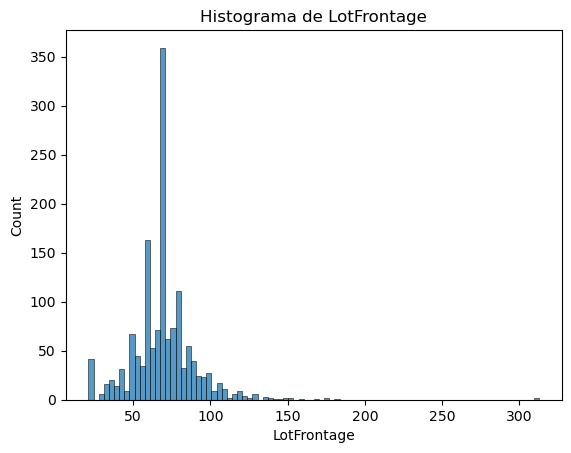

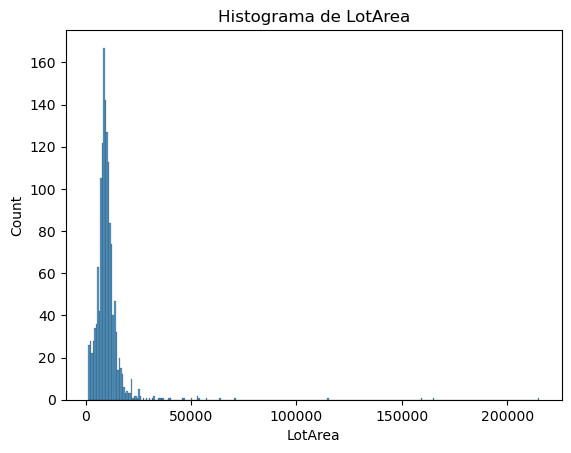

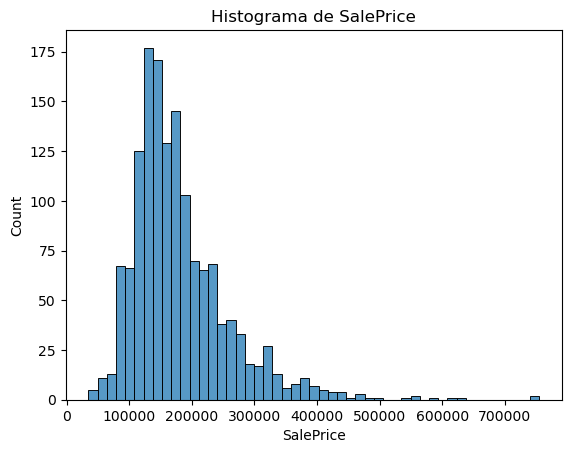

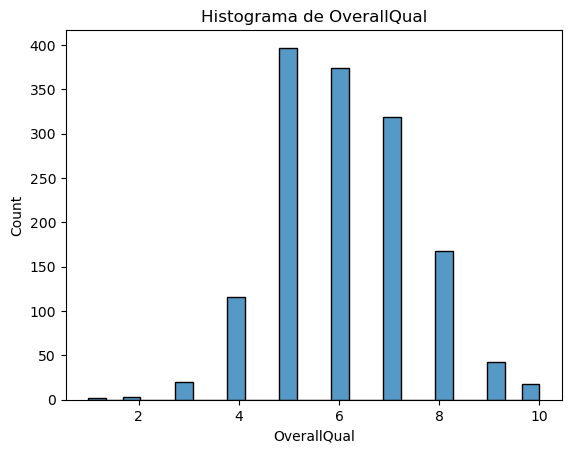

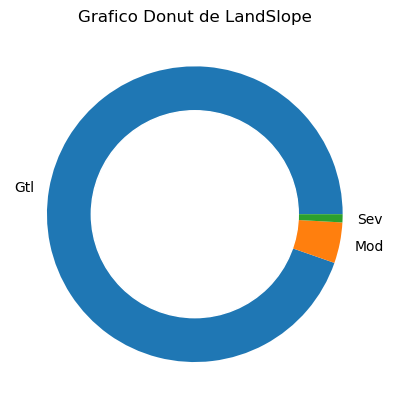

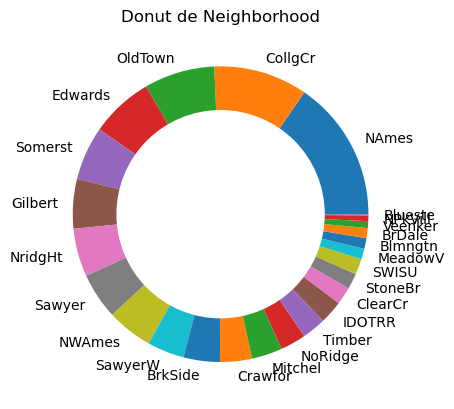

In [31]:
sns.histplot(datos['LotFrontage'])
plt.title('Histograma de LotFrontage')
plt.show()

sns.histplot(datos['LotArea'])
plt.title('Histograma de LotArea')
plt.show()

sns.histplot(datos['SalePrice'])
plt.title('Histograma de SalePrice')
plt.show()

sns.histplot(datos['OverallQual'])
plt.title('Histograma de OverallQual')
plt.show()

conteos_Landslope = datos['LandSlope'].value_counts()

plt.pie(conteos_Landslope.values, labels=conteos_Landslope.index)
my_circle = plt.Circle((0,0), 0.7, color='white')
p = plt.gcf()
p.gca().add_artist(my_circle)

plt.title('Grafico Donut de LandSlope')
plt.show()

conteos_barrios = datos['Neighborhood'].value_counts()

plt.pie(conteos_barrios.values, labels=conteos_barrios.index)
my_circle = plt.Circle((0,0), 0.7, color='white')
p = plt.gcf()
p.gca().add_artist(my_circle)

plt.title('Donut de Neighborhood')
plt.show()


En cuanto a los histogramas de LotFrontage, LotArea y SalePrice, las tres gráficas muestran una clara asimetría positiva. Esto indica que la gran mayoría de las casas tienen áreas y precios estándar (agrupados a la izquierda), pero existen unos pocos valores extremos que estiran la cola de la gráfica hacia la derecha.
Por otro lado, en el otro histograma, OverallQual, al ser una nota del 1 al 10, presenta una distribución mucho más simétrica y normal, con forma de campana, concentrándose el grueso de las viviendas en los niveles 5, 6 y 7.

En cuanto a los Gráficos de Donut, LandSlope muestra un desbalanceo extremo. Prácticamente el 95% de la tarta corresponde a la categoría "Gtl", haciendo que las otras categorías sean casi residuales. Por otro lado Neighborhood, muestra una alta fragmentación. Existen barrios con una gran cuota de mercado ("NAmes"), pero también hay muchísimos barrios minúsculos cuyas etiquetas se solapan porque apenas tienen viviendas registradas.

¿Qué decisiones tomaríamos a la vista de los resultados?

A la vista de los gráficos, tomaríamos dos principales decisiones. En primer lugar eliminar LandSlope por baja varianza, ya que casi el 100% de terrenos son llanos (Gtl) y no aporta poder predictivo.En segundo lugar agrupar los barrios minoritarios de Neighborhood en una categoría 'Otros' para evitar sobreajuste.

## 7


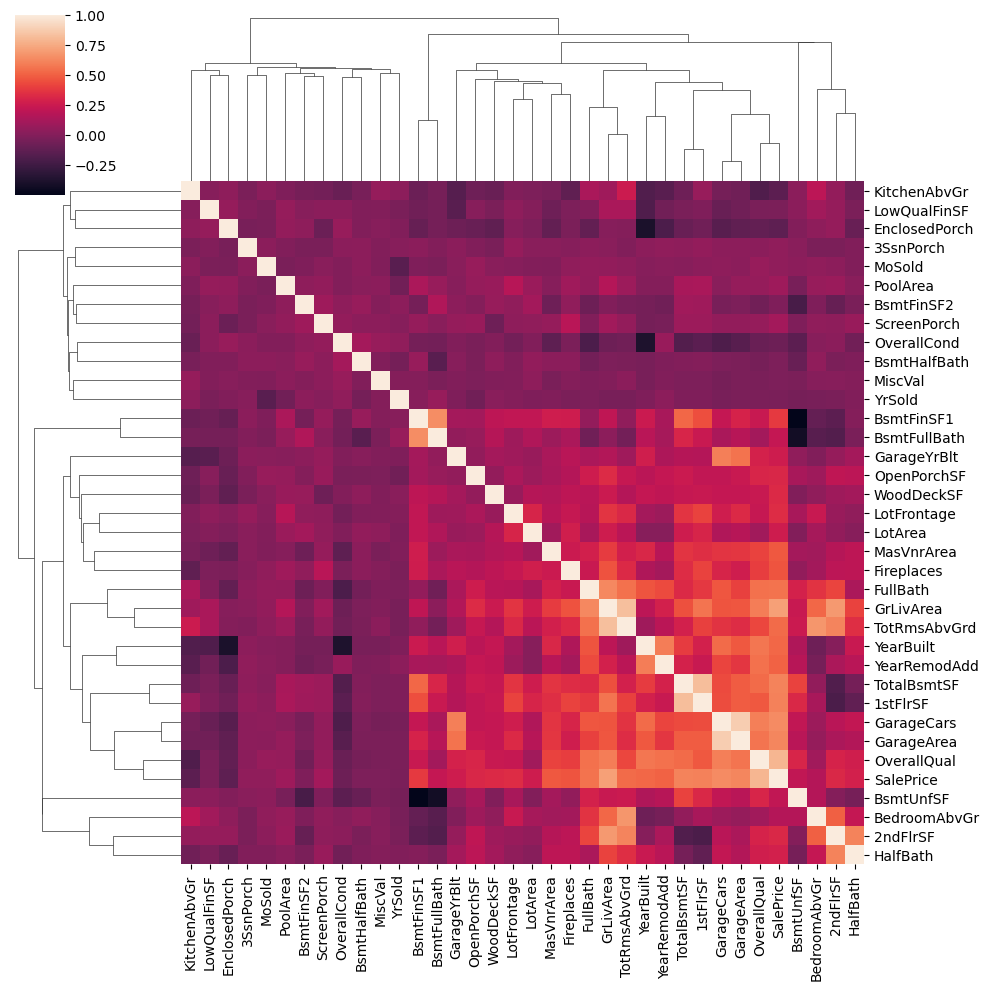

In [32]:
numericas = datos.select_dtypes(include=['int64', 'float64'])
matriz_corr = numericas.corr()
sns.clustermap(matriz_corr)
plt.show()

Interpretación del gráfico:
- Las ramas (agrupaciones): Mediante los dendrogramas de las esquinas, el algoritmo agrupa en ramas más cortas y cercanas aquellas variables que presentan un comportamiento matemático similar o redundante.
- Correlación con el precio ("SalePrice"): Observando la matriz, el precio de venta muestra una alta correlación positiva (cuadrados más claros/cálidos) con variables clave como "OverallQual" y "GrLivArea", indicando que son los principales factores que determinan el valor de una vivienda.
- Se aprecian variables que miden conceptos idénticos, como "GarageCars" y "GarageArea". Esto evidencia redundancia de información, por lo que la decisión técnica para un futuro modelo de Machine Learning sería eliminar una de ellas para evitar inestabilidad.